<a href="https://colab.research.google.com/github/KateT840/Espectrografia-astronomica/blob/main/Procesamiento_y_extracci%C3%B3n_del_perfil_de_un_espectro_solar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

# Subir la imagen solar y el dark
archivos = files.upload()

Saving sol ha derecha 20 seg.FIT to sol ha derecha 20 seg.FIT
Saving Imagen oscura 20s.FIT to Imagen oscura 20s.FIT


In [2]:
# Ver qué archivos se subieron
print(archivos.keys())

dict_keys(['sol ha derecha 20 seg.FIT', 'Imagen oscura 20s.FIT'])


In [3]:
nombre_solar = 'sol ha derecha 20 seg.FIT'
nombre_dark = 'Imagen oscura 20s.FIT'

with fits.open(nombre_solar) as hdul:
    solar = hdul[0].data.astype(float)

with fits.open(nombre_dark) as hdul:
    dark = hdul[0].data.astype(float)

print("Solar:", solar.shape)
print("Dark:", dark.shape)

Solar: (1020, 1530)
Dark: (1020, 1530)


In [4]:
solar_corregido = solar - dark

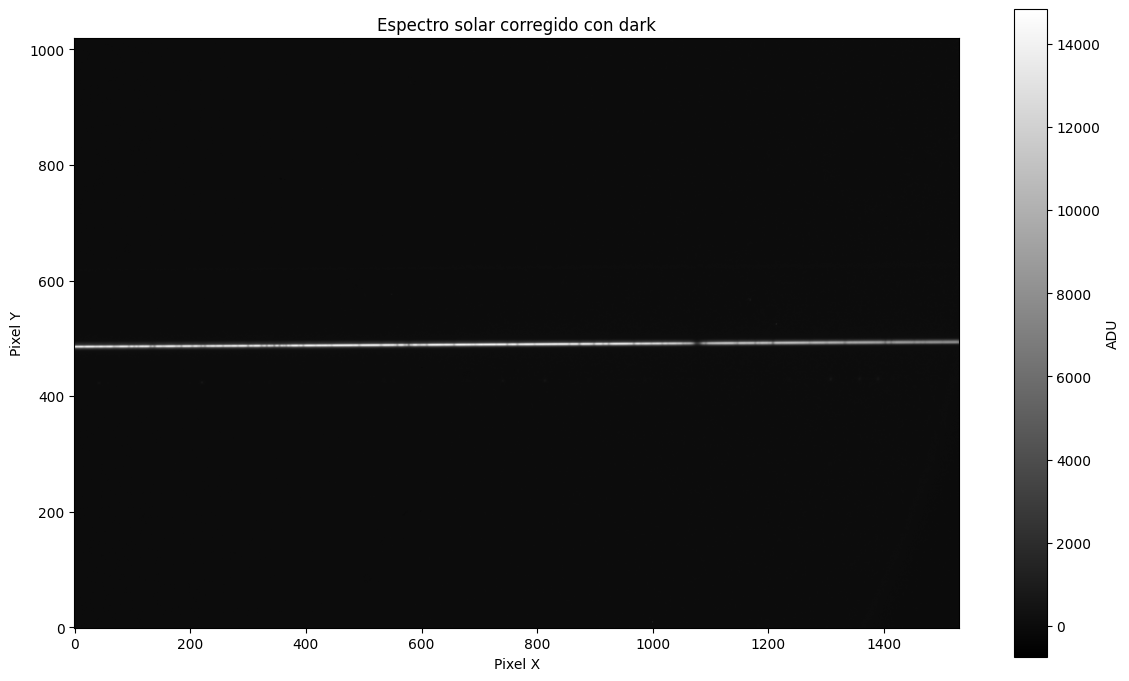

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
plt.figure(figsize=(12, 7))

plt.imshow(solar_corregido, cmap='gray', origin='lower')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.title('Espectro solar corregido con dark')
plt.colorbar(label='ADU')

plt.tight_layout()

plt.savefig('espectro_corregido.png', dpi=300, bbox_inches='tight')
plt.show()

from google.colab import files
files.download('espectro_corregido.png')

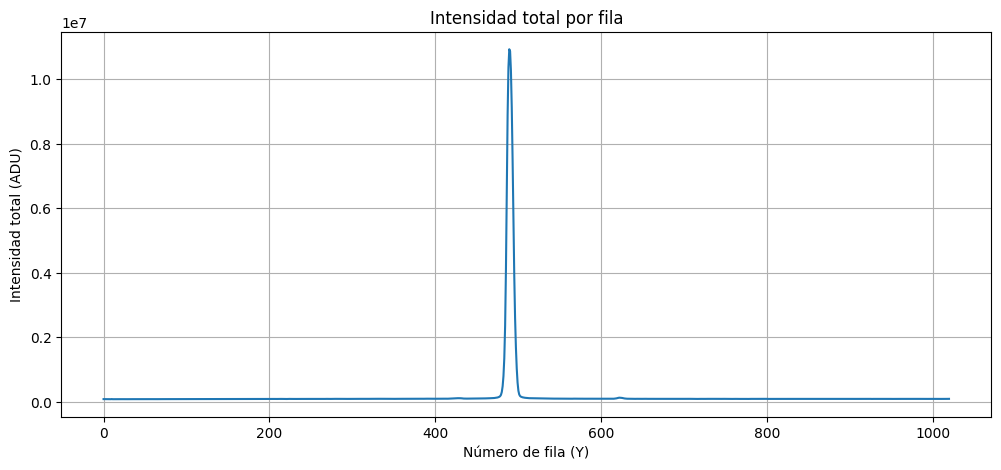

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# Sumar la intensidad de cada fila
intensidad_filas = np.sum(solar_corregido, axis=1)

plt.figure(figsize=(12, 5))
plt.plot(intensidad_filas)

plt.xlabel('Número de fila (Y)')
plt.ylabel('Intensidad total (ADU)')
plt.title('Intensidad total por fila')

plt.grid()
plt.savefig('localizacion_espectro.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('localizacion_espectro.png')

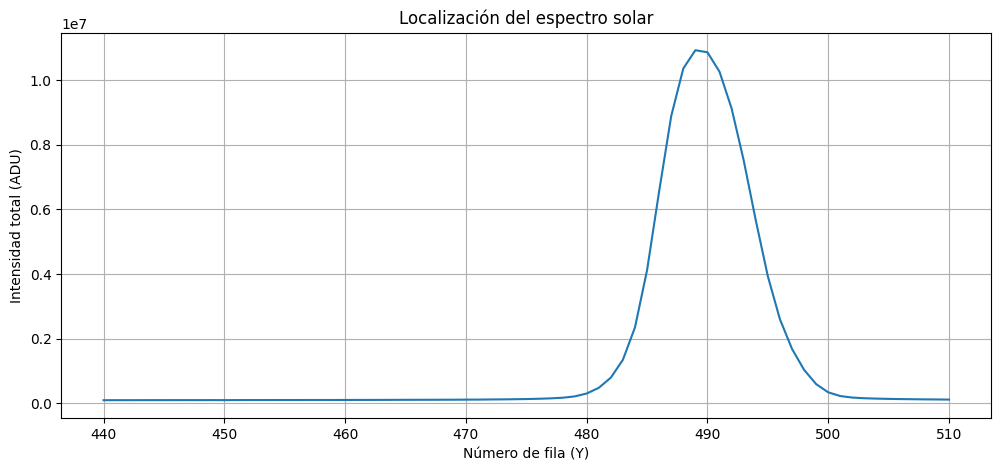

In [11]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(440, 511),
    intensidad_filas[440:511]
)

plt.xlabel('Número de fila (Y)')
plt.ylabel('Intensidad total (ADU)')
plt.title('Localización del espectro solar')

plt.grid()
plt.show()

In [12]:
region = intensidad_filas[440:511]

fila_max = np.argmax(region) + 440

print("Fila donde está el máximo:", fila_max)

Fila donde está el máximo: 489


In [13]:
y_centro = 489

y_inicio = y_centro - 5
y_final = y_centro + 6

print("Filas utilizadas:", y_inicio, "a", y_final - 1)

Filas utilizadas: 484 a 494


In [14]:
perfil = np.sum(
    solar_corregido[y_inicio:y_final, :],
    axis=0
)

print("Número de puntos del perfil:", len(perfil))

Número de puntos del perfil: 1530


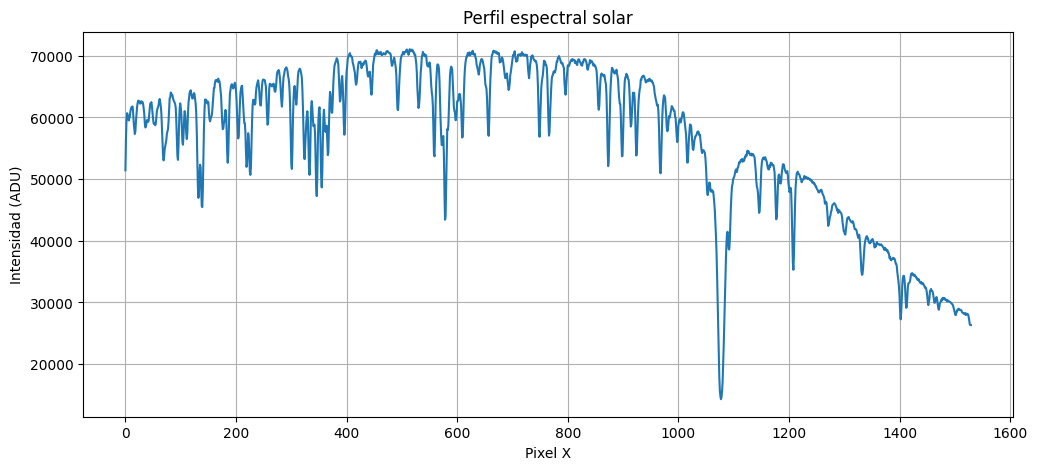

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
plt.figure(figsize=(12, 5))

plt.plot(perfil)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad (ADU)')
plt.title('Perfil espectral solar')

plt.grid()
plt.savefig('perfil_espectral.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('perfil_espectral.png')

In [16]:
perfil_normalizado = perfil / np.max(perfil)

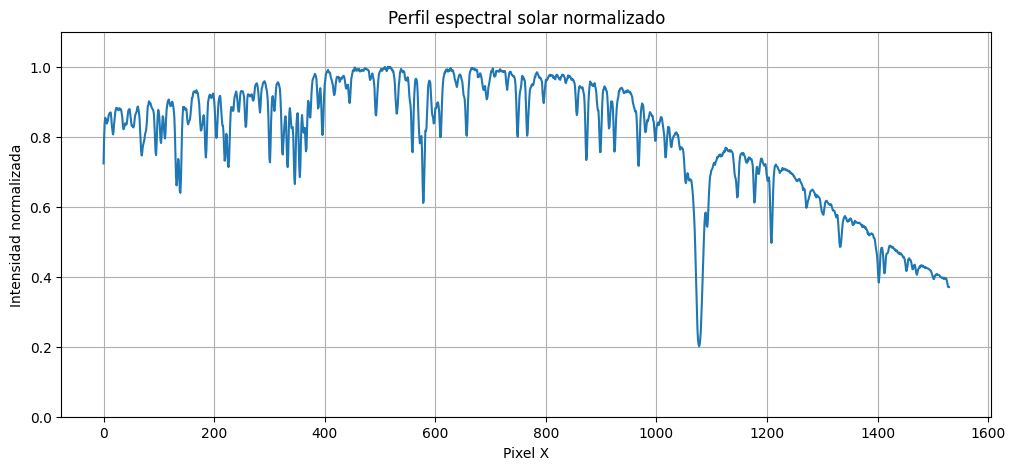

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(perfil_normalizado)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad normalizada')
plt.title('Perfil espectral solar normalizado')

plt.ylim(0, 1.1)
plt.grid()
plt.savefig('perfil_espectral_normalizado.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('perfil_espectral_normalizado.png')

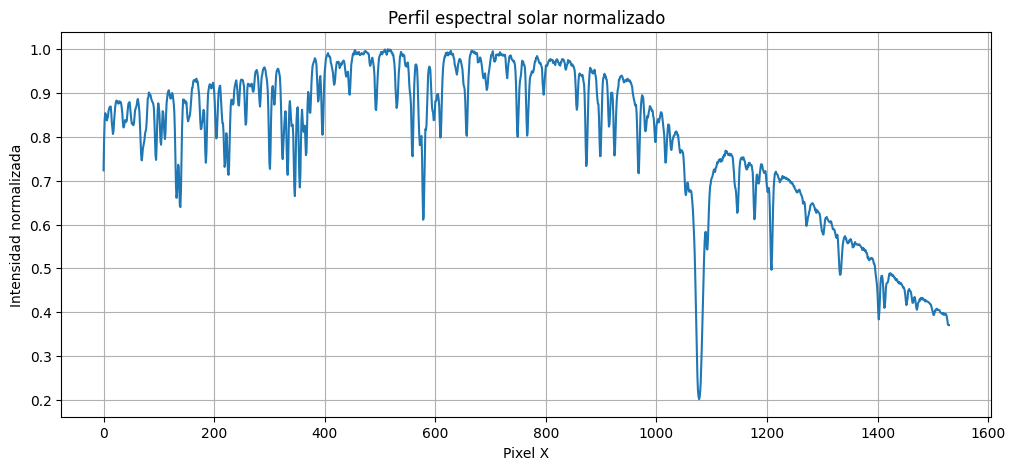

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(perfil_normalizado)

plt.xlabel('Pixel X')
plt.ylabel('Intensidad normalizada')
plt.title('Perfil espectral solar normalizado')

plt.grid()
plt.savefig('perfil_espectral_normalizado.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('perfil_espectral_normalizado.png')

In [26]:
region = perfil_normalizado[950:1251]

pixel_min = np.argmin(region) + 950
valor_min = np.min(region)

print("Pixel del mínimo:", pixel_min)
print("Intensidad mínima:", valor_min)

Pixel del mínimo: 1077
Intensidad mínima: 0.20128627318528525
